# Simple Momentum Strategy Backtest

An end-to-end momentum backtest on QQQ, TLT, GLD, RWO (daily data from 2016).

1. Compute daily returns from adjusted-close prices.
2. Build a momentum signal: each asset's trailing 252-day annualized Sharpe ratio.
3. Form an equal-weight long portfolio of assets with signal > 1.
4. Evaluate: annualized Sharpe overall and per year, correlation to the underlying assets, and cumulative returns.

_Uses the repo's `yahoo.py` downloader. Problem prompts paraphrased; all code is my own._

In [105]:
import importlib
import yahoo as yf
importlib.reload(yf)

univ = ['QQQ', 'TLT', 'GLD', 'RWO']
stock_px = yf.download(univ, start="2016-01-01")
ret = stock_px['Adj Close'] / stock_px['Adj Close'].shift()
ret

,QQQ,TLT,GLD,RWO
Date,,,,
2016-01-04,NaN,NaN,NaN,NaN
2016-01-05,0.998265,0.995965,1.002819,1.012116
2016-01-06,0.990395,1.013475,1.014441,0.992304
2016-01-07,0.968686,1.001795,1.014140,0.982120
2016-01-08,0.991799,1.004478,0.995572,0.984865
...,...,...,...,...
2026-07-30,1.032974,0.999397,1.016385,0.994971
2026-07-31,1.006496,0.993357,0.985099,0.994362
2026-08-03,1.017558,1.003296,1.000458,0.997067


In [106]:
import numpy as np

def compute_momentum(ret):
    momentum = ret.rolling(252).mean() / ret.rolling(252).std() * np.sqrt(252)
    return momentum

momentum = compute_momentum(ret)
momentum

,QQQ,TLT,GLD,RWO
Date,,,,
2016-01-04,NaN,NaN,NaN,NaN
2016-01-05,NaN,NaN,NaN,NaN
2016-01-06,NaN,NaN,NaN,NaN
2016-01-07,NaN,NaN,NaN,NaN
2016-01-08,NaN,NaN,NaN,NaN
...,...,...,...,...
2026-07-30,1301.641178,2705.905455,896.356840,1913.636169
2026-07-31,1301.116514,2703.151736,896.826064,1919.948691
2026-08-03,1297.097839,2701.523071,896.985039,1931.264692


In [107]:
def compute_portfolio(momentum):
    longs = momentum > 1
    count = longs.sum(axis=1)
    return longs.div(count, axis=0).fillna(0)

portfolio = compute_portfolio(momentum)
portfolio

,QQQ,TLT,GLD,RWO
Date,,,,
2016-01-04,0.00,0.00,0.00,0.00
2016-01-05,0.00,0.00,0.00,0.00
2016-01-06,0.00,0.00,0.00,0.00
2016-01-07,0.00,0.00,0.00,0.00
2016-01-08,0.00,0.00,0.00,0.00
...,...,...,...,...
2026-07-30,0.25,0.25,0.25,0.25
2026-07-31,0.25,0.25,0.25,0.25
2026-08-03,0.25,0.25,0.25,0.25


In [108]:
import numpy as np
port_ret = (portfolio.shift(1) * (ret - 1)).sum(axis=1)
asr_strategy = port_ret.mean() / port_ret.std() * np.sqrt(252)
asr_strategy

asr_year = port_ret.groupby(port_ret.index.year).apply(
    lambda x: x.mean() / x.std() * np.sqrt(252)
)
asr_year

corr_strategy = ret.corrwith(port_ret)
corr_strategy

/var/folders/jm/hww7by0d5mx4pxyf6_9387200000gn/T/ipykernel_1742/3956800749.py:7: RuntimeWarning: invalid value encountered in scalar divide
  lambda x: x.mean() / x.std() * np.sqrt(252)


QQQ    0.722904
TLT    0.368099
GLD    0.539081
RWO    0.731058
dtype: float64

<Axes: title={'center': 'Cumulative Strategy Returns'}, xlabel='Date'>

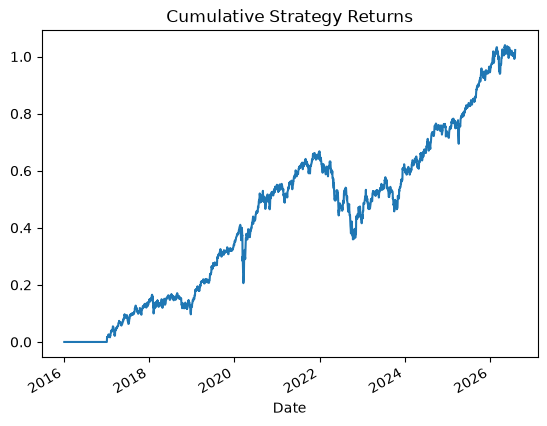

In [109]:
port_ret.cumsum().plot(title='Cumulative Strategy Returns')